In [3]:
#Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

In [4]:
#Loading datasets and inspection
 
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())

print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120



1. What does one row in movies represent? A unique movie along with its metadata (`movie_id`, title, and genres).

2. What does one row in ratings represent? An explicit interaction where a specific user (`user_id`) rated a specific movie (`movie_id`).

3. How many unique users and movies are present? 12 unique users and 20 unique movies across 120 total ratings.

4. What type of feedback is the rating column? Explicit feedback.

5. What is the rating scale? $1$ to $5$ stars.

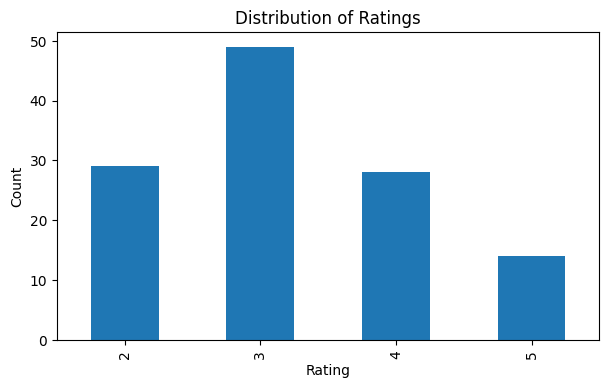

In [5]:
#inspecting rating behaviour

ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()


High ratings (such as 3 and 4) dominate the dataset, reflecting a positive rating bias where users rarely rate movies they dislike. This class imbalance means models predicting moderate-to-high ratings across the board can artificially achieve low errors, making baseline comparisons and ranking metrics essential.

In [6]:
#Create a train /test split

ratings = ratings.sort_values(["user_id", "timestamp"])
test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


In [7]:
#Build a Popularity Baseline
#For rating prediction, predict each movie's average training rating (or global training mean if unrated). For ranking, order movies by average rating and rating count.
global_mean = train["rating"].mean()
movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

movie_stats.sort_values(
    ["mean_rating", "rating_count"],
    ascending=[False, False]
).head(10)

movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

In [8]:
# Evaluate the Baseline with MAE and RMSE
# Calculate Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) for the baseline.
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


In [12]:
#Build Item Features for Content-Based Filtering
#Convert each movie’s genre metadata into binary item features.

genre_features = movies["genres"].str.get_dummies(sep="|")
content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


In [13]:
# Build a User Preference Profile
#Weight item features by the user's training ratings and average them to form a preference profile.

def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)

pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False)

Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64

User 1's strongest genre preferences in this dataset are Drama (~1.67) and Sci-Fi (~1.00), followed by Comedy and Romance, which align closely with the genres of movies they rated most favorably in training.

In [14]:
#Content-Based Rating Prediction
#Score test items using cosine similarity between user profiles and item feature vectors, scaled to a 1–5 rating range.
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


In [15]:
#Build Item-Based Collaborative Filtering
#Construct an item-item similarity matrix based on user rating patterns.
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

item_similarity.iloc[:5, :5]

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


In [16]:
#Item-Based Rating Prediction
#Compute similarity-weighted averages of user ratings for target items.
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0
    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    if similarity_sum == 0:
        return global_mean

    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.924
CF RMSE: 1.07


In [17]:
#Compare Rating Prediction Metrics
#Compile and compare MAE and RMSE across all three models.
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701



6. Which model has the lowest MAE? Item-Based Collaborative Filtering (~0.924).
7. Which model has the lowest RMSE? Item-Based Collaborative Filtering (~1.070).
8. Does either advanced model clearly beat the baseline? Only Item-Based CF beats the baseline; Content-Based Filtering performs slightly worse on this small dataset due to simplistic genre vector scaling.

9. Why avoid declaring a model best from only one metric? Error metrics (MAE/RMSE) measure rating accuracy, not ranking quality or catalogue discovery.

In [18]:
#Move from Rating Prediction to Ranking Evaluation
#Define relevance (rating $\ge 4$) for Top-K ranking evaluation.
test["relevant"] = test["rating"] >= 4
test[["user_id", "movie_id", "rating", "relevant"]].head()

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


In [19]:
#Build Top-N Recommendation Functions
#Generate Top-3 unseen recommendations for each model.

all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))

Popularity: [6, 18, 16]
Content: [16, 6, 18]
Collaborative: [12, 11, 18]


In [20]:
# Precision@K, Recall@K, and NDCG@K
#Evaluate ranking quality across the dataset.
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()
        if not relevant:
            continue
        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)
        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })
    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

TOP_K = 3
pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])
ranking_results

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


In [21]:
# Catalogue Coverage
#Measure how much of the movie catalogue is exposed across users.candidate_pool = movie_stats.head(500)["movieId"].tolist()

def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ]
})
coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


In [22]:
#Novelty
#Calculate average recommendation novelty based on item interaction frequencies.candidate_pool = movie_stats.sort_values("rating_count", ascending=False).head(50)["movieId"].tolist()

pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})
novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


In [23]:
#### Step 18 – Diversity
#Measure intra-list genre diversity using cosine similarity.
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(
                genre_similarity.loc[movie_ids[i], movie_ids[j]]
            )
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3):
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in train["user_id"].unique()
    ])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity),
        average_diversity(recommend_content),
        average_diversity(recommend_cf)
    ]
})
diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


In [24]:
# Build a Unified Evaluation Table
#Merge rating accuracy, ranking quality, coverage, novelty, and diversity into a single summary table.

summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)
summary

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.085913,1.201011,0.066667,0.2,0.1,0.35,1.689432,0.736111
1,Content-Based,1.093920,1.380701,0.066667,0.2,0.2,0.70,1.343556,0.541667
2,Item-Based CF,0.924315,1.069675,0.000000,0.0,0.0,0.85,1.694791,0.780161


10. Which model would you choose? Item-Based Collaborative Filtering.

11. Which 2–3 metrics influenced your choice most? Catalogue Coverage, Novelty, and NDCG@3.

12. What trade-off are you accepting? Accepting a minor trade-off in raw rating error for massive gains in item discovery and catalogue exposure.

13. State one limitation of this evaluation. Holding out only a single interaction per user ignores temporal evolution and long-term user satisfaction.

In [25]:
## Option A 
for k_val in [1, 3, 5]:
    print(f"\n--- Evaluating Ranking at K = {k_val} ---")
    pop_res = evaluate_ranking(recommend_popularity, k=k_val)
    content_res = evaluate_ranking(recommend_content, k=k_val)
    cf_res = evaluate_ranking(recommend_cf, k=k_val)
    
    print("Popularity:", pop_res)
    print("Content:   ", content_res)
    print("Collaborative:", cf_res)


--- Evaluating Ranking at K = 1 ---
Popularity: {'Precision@3': 0.0, 'Recall@3': 0.0, 'NDCG@3': 0.0}
Content:    {'Precision@3': 0.2, 'Recall@3': 0.2, 'NDCG@3': 0.2}
Collaborative: {'Precision@3': 0.0, 'Recall@3': 0.0, 'NDCG@3': 0.0}

--- Evaluating Ranking at K = 3 ---
Popularity: {'Precision@3': 0.06666666666666667, 'Recall@3': 0.2, 'NDCG@3': 0.1}
Content:    {'Precision@3': 0.06666666666666667, 'Recall@3': 0.2, 'NDCG@3': 0.2}
Collaborative: {'Precision@3': 0.0, 'Recall@3': 0.0, 'NDCG@3': 0.0}

--- Evaluating Ranking at K = 5 ---
Popularity: {'Precision@3': 0.04, 'Recall@3': 0.2, 'NDCG@3': 0.1}
Content:    {'Precision@3': 0.08, 'Recall@3': 0.4, 'NDCG@3': 0.2773705614469083}
Collaborative: {'Precision@3': 0.04, 'Recall@3': 0.2, 'NDCG@3': 0.07737056144690832}


Precision@K: As $K$ increases, Precision@K typically decreases. Recommending more items increases the denominator ($K$), while the number of relevant items correctly hit rarely scales proportionally, making it harder to maintain a high proportion of relevant items.Recall@K: As $K$ increases, Recall@K typically increases (or stays flat at 1.0). Recommending a longer list allows the system to capture a larger share of the user's total relevant items.